In M124 HW09 we use `using PyCall, PyPlot   # Packages needed`
```julia
    @pyimport IPython.display as d
    function anim(sol::IVPsolution)
        animation = pyimport("matplotlib.animation");
        fig, ax = subplots(figsize=(5,5))
        function update(frame)
            θ1 = sol.y[frame+1,1]
            θ2 = sol.y[frame+1,2]
            p1 = [sin(θ1),-cos(θ1)]
            p2 = p1 .+ [sin(θ2),-cos(θ2)]
            ax.clear()
            ax.plot([0,p1[1],p2[1]], [0,p1[2],p2[2]], linewidth=2)
            ax.add_artist(matplotlib.patches.Circle(p1, 0.1))
            ax.add_artist(matplotlib.patches.Circle(p2, 0.1))
            ax.set_xlim([-2.5,2.5])
            ax.set_ylim([-2.5,2.5])
        end

        ani = animation.FuncAnimation(fig, update, frames=length(sol.t), interval=50)
        close(ani._fig)
        d.HTML(ani.to_jshtml())
    end
```
But I remember we move to `Plots` Thus, I will find a UI which match Plots later....

In [2]:
include("../src/load_all.jl")

Loaded successfully.


In [3]:
case = LaxCase.make_case(nx=100, ny=2, degree=0, final_time=1)
solution = Solver.raw_solve_2d(case; time_method=:SSPRK3, verbose=true, save_every=50, dt_max=case.final_time/20)
(solution.time, solution.number_of_steps, solution.number_of_retries)

step=1 time=0.0037224861056497555 dt=0.0037224861056497555 retries=0
step=2 time=0.007382511937818767 dt=0.0036600258321690107 retries=0
step=3 time=0.010988386314819708 dt=0.003605874377000941 retries=0
step=4 time=0.01454696768608061 dt=0.003558581371260902 retries=0
step=5 time=0.018064004450291375 dt=0.0035170367642107666 retries=0
step=6 time=0.021544377843242875 dt=0.003480373392951501 retries=0
step=7 time=0.024992278915795686 dt=0.0034479010725528094 retries=0
step=8 time=0.02841133990068252 dt=0.003419060984886834 retries=0
step=9 time=0.03180473340793159 dt=0.0033933935072490745 retries=0
step=10 time=0.035175248558760926 dt=0.003370515150829333 retries=0
step=11 time=0.03852535035635457 dt=0.0033501017975936485 retries=0
step=12 time=0.04185722672087325 dt=0.003331876364518679 retries=0
step=13 time=0.04517282634351409 dt=0.003315599622640843 retries=0
step=14 time=0.04847388963229197 dt=0.003301063288777877 retries=0
step=15 time=0.051761974400454776 dt=0.003288084768162804

(1.0, 313, 0)

In [4]:
Diagnostics.conservation_report(solution)

(initial_total_ls = [0.47250000000000075, 0.1553050000000003, 0.0, 5.177951444999991], final_total_ls = [0.4725000000000007, 0.4509978184510115, 2.7413272856375242e-17, 5.424217918076107], change_ls = [-5.551115123125783e-17, 0.2956928184510112, 2.7413272856375242e-17, 0.24626647307611638], boundary_change_ls = [0.0, 0.29569281845101786, 2.7413272856421412e-17, 0.2462664730761867], balance_error_ls = [-5.551115123125783e-17, -6.661338147750939e-15, -4.616993337080633e-29, -7.033262861000367e-14])

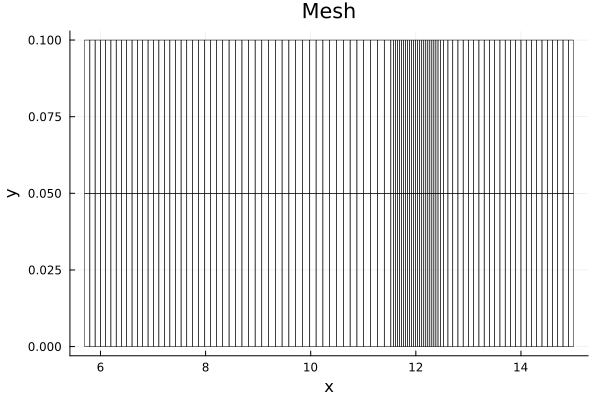

In [5]:
display(Visualization.plot_mesh(solution.state,case.mesh))

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasedensitywith_degree=0.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasedensitywith_degree=0.gif")
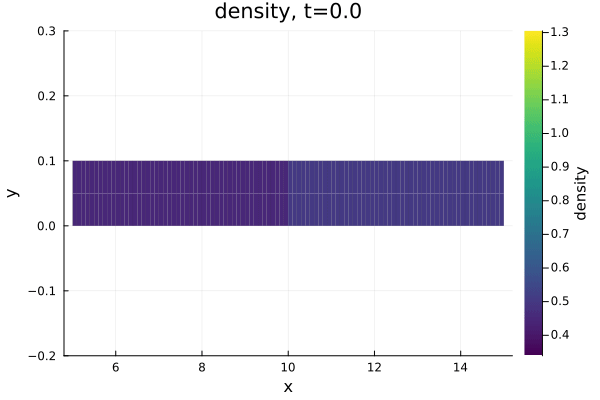

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasepressurewith_degree=0.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasepressurewith_degree=0.gif")
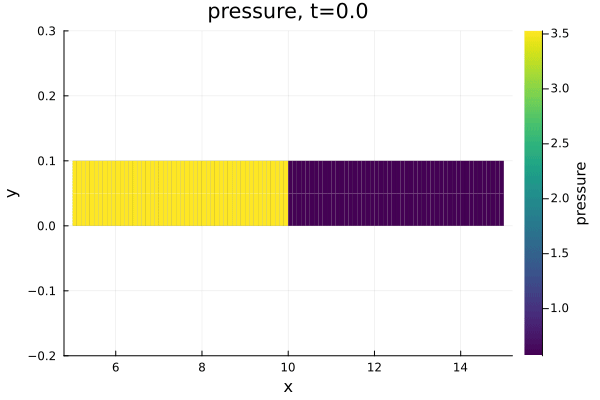

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasevelocity_xwith_degree=0.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasevelocity_xwith_degree=0.gif")
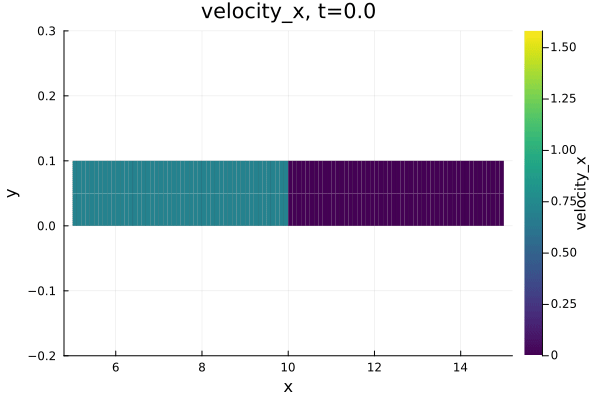

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasevelocity_ywith_degree=0.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasevelocity_ywith_degree=0.gif")
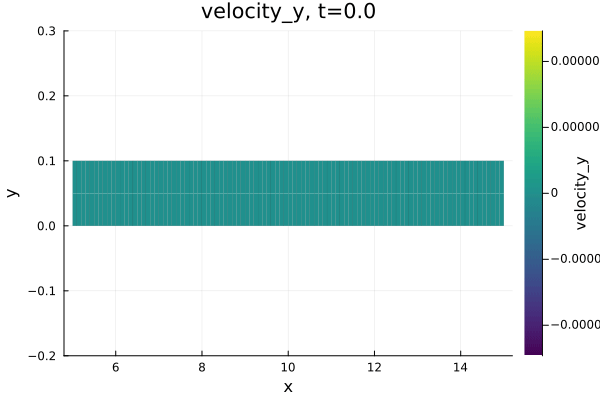

In [6]:
for field in (:density, :pressure, :velocity_x, :velocity_y)
    gif_result = Visualization.draw_gif(
        solution,
        "../results/LaxCase$(field)with_degree=0.gif";
        field = field,
        fps = 10,
    )
    display(gif_result)
end
# plot this is very very slow!!!!!!!!!!!

## Try to directly use the original method on this lax problem for fun

In [7]:
case = LaxCase.make_case(nx=100, ny=2, degree=1, final_time=0.2)
solution = Solver.raw_solve_2d(case; time_method=:SSPRK3, verbose=true, save_every=10, dt_max=case.final_time/20)
(solution.time, solution.number_of_steps, solution.number_of_retries)

step=1 time=0.0037224861056497555 dt=0.0037224861056497555 retries=0
step=2 time=0.005548893761250906 dt=0.0018264076556011508 retries=1
step=3 time=0.0073576695020573955 dt=0.0018087757408064892 retries=1
step=4 time=0.007581586712503486 dt=0.0002239172104460904 retries=4
step=5 time=0.007693410919160191 dt=0.00011182420665670502 retries=5
step=6 time=0.007749289491608869 dt=5.587857244867853e-5 retries=6
step=7 time=0.007756272219655588 dt=6.982728046718532e-6 retries=9
step=8 time=0.007759763452895495 dt=3.4912332399070737e-6 retries=10


LoadError: DomainError with 51:
nonphysical polynomial value at point=(10.09754675593892, 0.0): rho=0.46601980867085196, p=-0.00010058359162061213

### I accidently find a very weird result.

In [8]:
case = LaxCase.make_case(nx=10, ny=2, degree=2, final_time=0.2)
solution = Solver.raw_solve_2d(case; time_method=:SSPRK3, verbose=true, save_every=10, dt_max=case.final_time/20)
(solution.time, solution.number_of_steps, solution.number_of_retries)

step=1 time=0.0037224861056497555 dt=0.0037224861056497555 retries=0
step=2 time=0.007438468795187362 dt=0.003715982689537607 retries=0
step=3 time=0.011148224246714616 dt=0.003709755451527253 retries=0
step=4 time=0.014851961822931723 dt=0.0037037375762171074 retries=0
step=5 time=0.018549832335893288 dt=0.0036978705129615632 retries=0
step=6 time=0.022241936623502573 dt=0.0036921042876092835 retries=0
step=7 time=0.025928332924073757 dt=0.003686396300571185 retries=0
step=8 time=0.02960904423285528 dt=0.0036807113087815252 retries=0
step=9 time=0.033284064128403304 dt=0.0036750198955480227 retries=0
step=10 time=0.03695336197541927 dt=0.0036692978470159636 retries=0
step=11 time=0.04061688801776896 dt=0.0036635260423496852 retries=0
step=12 time=0.0442745777567392 dt=0.003657689738970246 retries=0
step=13 time=0.0479263556319081 dt=0.003651777875168896 retries=0
step=14 time=0.051572138157348964 dt=0.0036457825254408633 retries=0
step=15 time=0.055211838176415395 dt=0.003639700019066

(0.2, 58, 2)

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasedensitywith_degree=2.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasedensitywith_degree=2.gif")
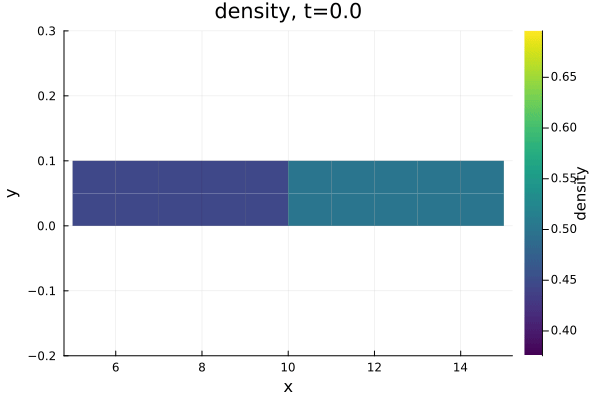

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasepressurewith_degree=2.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasepressurewith_degree=2.gif")
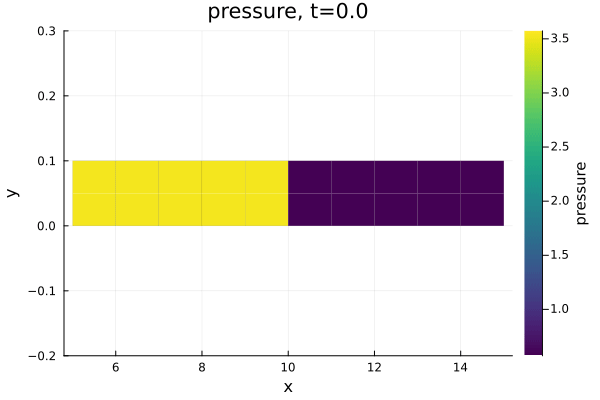

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasevelocity_xwith_degree=2.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasevelocity_xwith_degree=2.gif")
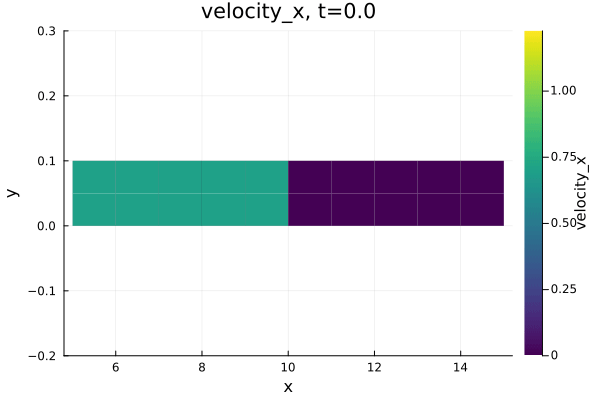

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\LaxCasevelocity_ywith_degree=2.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\LaxCasevelocity_ywith_degree=2.gif")
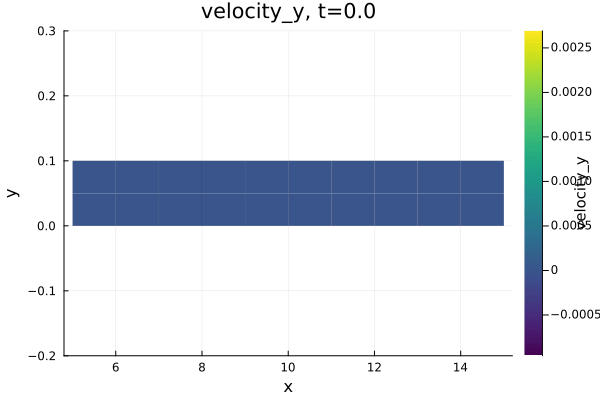

In [9]:
for field in (:density, :pressure, :velocity_x, :velocity_y)
    gif_result = Visualization.draw_gif(
        solution,
        "../results/LaxCase$(field)with_degree=2.gif";
        field = field,
        fps = 10,
    )
    display(gif_result)
end